# 34. Amplitude against distance

How the airwave and the ground motion decay from 11.8 to 21.3 km, and what that says about the source:

* **blast-wave parameters** at each working infraBSU: positive and negative peak overpressure, positive-phase
  duration $t_+$ and positive impulse $I_+$ (broadband, >0.05 Hz);
* **band-split peaks** (0.05–4 Hz and 4–40 Hz), since notebook 30 found that spherical spreading holds
  below 4 Hz but not above;
* the **effect of B20's 100 samples/s**, measured by decimating the 500 samples/s records;
* **decay exponents**: $A \propto r^{-n}$, fitted per metric (four distances, so indicative);
* a first, order-of-magnitude **TNT-equivalent yield** from the Kinney & Graham (1985) relations for peak
  overpressure and positive-phase duration;
* **ground-motion amplitudes** against distance: the air-coupled peak velocity and the seismic wavetrain
  ahead of the airwave (notebook 26).

The infraBSU peaks still carry the relative calibration uncertainty (the B14 sensors spread by up to 22%);
the Artemis II calibrations should be applied before these numbers are final.

Output (`cfg.OUT_DIR / "34_amplitude_vs_distance"`): `blast_parameters.csv`, `decay_fits.csv`,
`decimation_effect.csv`, `yield_estimates.csv`, `ground_motion_amplitudes.csv`, `amplitude_vs_distance.png`,
`blast_waveforms.png`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import newglenn_config as cfg

warnings.filterwarnings('ignore', message='ObsPy can not map unit')
ORIGIN = cfg.ORIGIN
OUT = cfg.output_dir('34_amplitude_vs_distance')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
stations = cfg.station_table()
air = cfg.airwave_speeds()
wx = cfg.weather_at_origin()[2]
P0 = float(wx['pressure_pa'])
PRESSURE = ['1R.B20.00.HD1', '1R.B14.00.CD0', '1R.B14.00.CD1', '1R.B14.00.CD2', '1R.B29.00.CD0', '1R.B05.00.CD0']
VERTICAL = ['1R.B20.00.HHZ', '1R.B14.00.CHZ', '1R.B29.00.CHZ', '1R.B05.00.CHZ']
HP = 0.05                                  # Hz, high-pass for blast parameters (infraBSU corner ~21 s)
raw = cfg.event_stream_raw(starttime=ORIGIN - 300, endtime=ORIGIN + 300)
st = cfg.instrument_correct(raw)
print('ambient pressure', P0, 'Pa')

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/.claude/worktrees/newglenn-paper-7faf3d/ksclib/src/ksclib/centaur.py:136: UserWarning: B14: no Centaur response before 2026-05-29T01:00:02.370000Z; using 1R.B14_20260614T135243Z.xml (16.5 days later)
  warnings.warn(str(m.message))


ambient pressure 101395.0 Pa


## Blast-wave parameters

For each pressure record (high-passed at 0.05 Hz, baseline = median of the 17 s before the arrival window):
the positive peak $P_+$, the most negative value in the following 12 s $P_-$, the positive phase (the
zero-to-zero interval containing $P_+$), its duration $t_+$ and impulse $I_+ = \int p\,dt$ over it.

In [2]:
def blast(tr, hp=HP):
    t = tr.copy().filter('highpass', freq=hp, corners=2, zerophase=True)
    ta = air.travel_time_s[tr.stats.station]
    base = np.median(t.slice(ORIGIN + ta - 20, ORIGIN + ta - 3).data)
    s = t.slice(ORIGIN + ta - 3, ORIGIN + ta + 12)
    fs = s.stats.sampling_rate
    y = s.data - base
    tt = s.times() - 3
    ip = int(np.argmax(y))
    i0 = ip
    while i0 > 0 and y[i0 - 1] > 0:
        i0 -= 1
    i1 = ip
    while i1 < len(y) - 1 and y[i1 + 1] > 0:
        i1 += 1
    return dict(P_pos_Pa=y[ip], P_neg_Pa=y[ip:].min(), t_pos_s=(i1 - i0 + 1) / fs,
                I_pos_Pa_s=np.trapezoid(y[i0:i1 + 1], dx=1 / fs), t_peak_s=ta + tt[ip], fs=fs), (tt, y, i0, i1)

rows, wave = [], {}
for sid in PRESSURE:
    tr = st.select(id=sid)[0]
    m, w = blast(tr)
    sta = tr.stats.station
    r_m = air.distance_m[sta]
    lo = tr.copy().filter('bandpass', freqmin=HP, freqmax=4.0, corners=4, zerophase=True)
    hi = tr.copy().filter('bandpass', freqmin=4.0, freqmax=min(40.0, 0.45 * tr.stats.sampling_rate), corners=4, zerophase=True)
    ta = air.travel_time_s[sta]
    win = (ORIGIN + ta - 3, ORIGIN + ta + 12)
    m.update(P_low_0p05_4Hz_Pa=np.abs(lo.slice(*win).data).max(), P_high_4_40Hz_Pa=np.abs(hi.slice(*win).data).max())
    rows.append(dict(id=sid, station=sta, distance_km=r_m / 1000, **m))
    wave[sid] = w
bp = pd.DataFrame(rows).sort_values(['distance_km', 'id']).reset_index(drop=True)
bp['P_pos_x_r_kPa_km'] = bp.P_pos_Pa * bp.distance_km / 1000
bp['I_pos_x_r_Pa_s_km'] = bp.I_pos_Pa_s * bp.distance_km
bp.to_csv(OUT / 'blast_parameters.csv', index=False)
display(bp.round(3))

,id,station,distance_km,P_pos_Pa,P_neg_Pa,t_pos_s,I_pos_Pa_s,t_peak_s,fs,P_low_0p05_4Hz_Pa,P_high_4_40Hz_Pa,P_pos_x_r_kPa_km,I_pos_x_r_Pa_s_km
0,1R.B20.00.HD1,B20,11.793,407.412,-124.658,0.440,61.272,34.341,100.0,326.752,136.661,4.805,722.604
1,1R.B14.00.CD0,B14,19.312,263.539,-92.280,0.382,42.084,56.149,500.0,170.152,122.044,5.089,812.710
2,1R.B14.00.CD1,B14,19.312,341.826,-110.521,0.384,54.425,56.149,500.0,221.659,157.914,6.601,1051.047
3,1R.B14.00.CD2,B14,19.312,272.827,-85.755,0.384,42.268,56.149,500.0,171.795,122.534,5.269,816.277
4,1R.B29.00.CD0,B29,21.003,315.235,-43.436,0.358,27.646,61.584,500.0,155.753,162.721,6.621,580.639
5,1R.B05.00.CD0,B05,21.304,272.962,-60.582,0.372,30.352,62.118,500.0,159.316,117.826,5.815,646.613


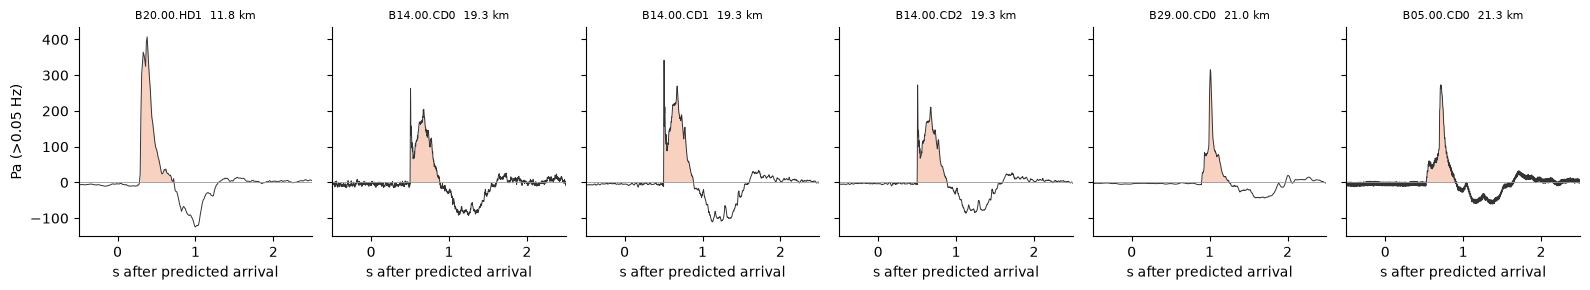

In [3]:
fig, axs = plt.subplots(1, len(PRESSURE), figsize=(16, 3), sharey=True)
for ax, sid in zip(axs, bp.id):
    tt, y, i0, i1 = wave[sid]
    ax.plot(tt, y, color='#333333', lw=0.7)
    ax.fill_between(tt[i0:i1 + 1], 0, y[i0:i1 + 1], color='#eb6834', alpha=0.3, lw=0)
    ax.axhline(0, color='#999999', lw=0.6)
    ax.set(xlim=(-0.5, 2.5), xlabel='s after predicted arrival')
    ax.set_title(f"{sid.replace('1R.', '')}  {stations.distance_km[sid.split('.')[1]]:.1f} km", fontsize=8)
axs[0].set_ylabel('Pa (>0.05 Hz)')
fig.tight_layout()
fig.savefig(OUT / 'blast_waveforms.png', dpi=150, bbox_inches='tight')

## How much does 100 samples/s lose?

Each 500 samples/s record is low-passed at 40 Hz and decimated to 100 samples/s, as B20 is recorded, and
the blast parameters are measured again.

In [4]:
rows = []
for sid in PRESSURE:
    tr = st.select(id=sid)[0]
    if tr.stats.sampling_rate <= 100:
        continue
    d = tr.copy()
    d.filter('lowpass', freq=40, corners=8, zerophase=True)
    d.resample(100, no_filter=True)
    a, _ = blast(tr)
    b, _ = blast(d)
    rows.append(dict(id=sid, P_pos_500=a['P_pos_Pa'], P_pos_100=b['P_pos_Pa'], ratio_P=b['P_pos_Pa'] / a['P_pos_Pa'],
                     ratio_I=b['I_pos_Pa_s'] / a['I_pos_Pa_s'], ratio_t=b['t_pos_s'] / a['t_pos_s']))
dec = pd.DataFrame(rows)
dec.to_csv(OUT / 'decimation_effect.csv', index=False)
display(dec.round(3))
print(f"Peak at 100 samples/s is {dec.ratio_P.min():.2f}-{dec.ratio_P.max():.2f} of the 500 samples/s peak; "
      f"impulse {dec.ratio_I.min():.2f}-{dec.ratio_I.max():.2f}.")

,id,P_pos_500,P_pos_100,ratio_P,ratio_I,ratio_t
0,1R.B14.00.CD0,263.539,193.306,0.734,0.992,1.021
1,1R.B14.00.CD1,341.826,254.485,0.744,0.992,1.016
2,1R.B14.00.CD2,272.827,197.409,0.724,0.991,1.016
3,1R.B29.00.CD0,315.235,303.383,0.962,0.995,1.006
4,1R.B05.00.CD0,272.962,268.720,0.984,0.992,1.022


Peak at 100 samples/s is 0.72-0.98 of the 500 samples/s peak; impulse 0.99-1.00.


## Decay with distance

One value per station (B14: mean of its three infraBSUs), fitted as $\log A = a - n \log r$. With four
stations spanning a factor of 1.8 in distance, and B20 possibly low by up to the decimation loss above,
the exponents are indicative. A fit without B20 uses only 19.3–21.3 km and is not meaningful, so B20's
peak is also shown corrected by the largest decimation loss.

In [5]:
METRICS = {'P_pos_Pa': 'P+ (Pa)', 'P_neg_Pa': '|P-| (Pa)', 'I_pos_Pa_s': 'I+ (Pa s)', 't_pos_s': 't+ (s)',
           'P_low_0p05_4Hz_Pa': 'peak 0.05-4 Hz (Pa)', 'P_high_4_40Hz_Pa': 'peak 4-40 Hz (Pa)'}
per = bp.groupby('station').agg(distance_km=('distance_km', 'first'), **{k: (k, lambda x: np.mean(np.abs(x))) for k in METRICS})
per = per.sort_values('distance_km')
fits = []
for k, lab in METRICS.items():
    for label, data in (('all', per), ('B20 peak corrected', None)):
        d = per.copy()
        if label != 'all':
            if k not in ('P_pos_Pa', 'P_high_4_40Hz_Pa'):
                continue
            d.loc['B20', k] = d.loc['B20', k] / dec.ratio_P.min()
        x, y = np.log10(d.distance_km), np.log10(d[k])
        A = np.vstack([np.ones_like(x), x]).T
        coef, res, *_ = np.linalg.lstsq(A, y, rcond=None)
        dof = len(x) - 2
        s2 = float(res[0]) / dof if len(res) and dof > 0 else np.nan
        se = np.sqrt(s2 * np.linalg.inv(A.T @ A)[1, 1]) if np.isfinite(s2) else np.nan
        fits.append(dict(metric=lab, data=label, n=-coef[1], n_se=se, value_at_10km=10 ** (coef[0] + coef[1])))
fits = pd.DataFrame(fits)
fits.to_csv(OUT / 'decay_fits.csv', index=False)
display(per.round(3))
display(fits.round(2))

,distance_km,P_pos_Pa,P_neg_Pa,I_pos_Pa_s,t_pos_s,P_low_0p05_4Hz_Pa,P_high_4_40Hz_Pa
station,,,,,,,
B20,11.793,407.412,124.658,61.272,0.440,326.752,136.661
B14,19.312,292.731,96.185,46.259,0.383,187.869,134.164
B29,21.003,315.235,43.436,27.646,0.358,155.753,162.721
B05,21.304,272.962,60.582,30.352,0.372,159.316,117.826


,metric,data,n,n_se,value_at_10km
0,P+ (Pa),all,0.58,0.15,446.68
1,P+ (Pa),B20 peak corrected,1.15,0.18,674.30
2,|P-| (Pa),all,1.35,0.71,163.82
3,I+ (Pa s),all,1.16,0.45,77.13
4,t+ (s),all,0.31,0.05,0.46
5,peak 0.05-4 Hz (Pa),all,1.23,0.09,402.68
6,peak 4-40 Hz (Pa),all,-0.00,0.33,136.69
7,peak 4-40 Hz (Pa),B20 peak corrected,0.57,0.34,206.35


## TNT-equivalent yield (order of magnitude)

Kinney & Graham (1985) give, for a free-air TNT explosion of mass $W$ at scaled distance $Z = r/W^{1/3}$
(m kg$^{-1/3}$):

$$\frac{P_+}{P_0} = \frac{808\,[1 + (Z/4.5)^2]}{\sqrt{[1 + (Z/0.048)^2][1 + (Z/0.32)^2][1 + (Z/1.35)^2]}},\qquad
\frac{t_+}{W^{1/3}} = \frac{980\,[1 + (Z/0.54)^{10}]}{[1 + (Z/0.02)^3][1 + (Z/0.74)^6]\sqrt{1 + (Z/6.9)^2}}\ \mathrm{ms\,kg^{-1/3}}.$$

Each is solved for $W$ at each station. A surface burst reflects from the ground, roughly doubling the
effective yield, so the TNT mass is about half the free-air value. **Caveats:** the relations are fitted
to condensed explosives at much smaller scaled distances (here $Z$ is in the hundreds); a propellant
explosion releases energy more slowly than TNT (longer, weaker pulse); and night-time refraction
(notebooks 24 and 30) can raise far-field amplitudes. The two estimates bracket the yield to within an
order of magnitude at best.

In [6]:
from scipy.optimize import brentq

def kg_ratio(Z):
    return 808 * (1 + (Z / 4.5) ** 2) / np.sqrt((1 + (Z / 0.048) ** 2) * (1 + (Z / 0.32) ** 2) * (1 + (Z / 1.35) ** 2))

def kg_td(Z):            # ms per kg^(1/3)
    return 980 * (1 + (Z / 0.54) ** 10) / ((1 + (Z / 0.02) ** 3) * (1 + (Z / 0.74) ** 6) * np.sqrt(1 + (Z / 6.9) ** 2))

def yield_from_p(p, r):
    f = lambda lw: kg_ratio(r / 10 ** (lw / 3)) - p / P0  # noqa: E731
    return 10 ** brentq(f, -3, 12)

def yield_from_t(t, r):
    f = lambda lw: kg_td(r / 10 ** (lw / 3)) * 10 ** (lw / 3) / 1000 - t  # noqa: E731
    return 10 ** brentq(f, -3, 12)

rows = []
for _, r in bp.iterrows():
    rm = r.distance_km * 1000
    wp, wt = yield_from_p(r.P_pos_Pa, rm), yield_from_t(r.t_pos_s, rm)
    rows.append(dict(id=r.id, distance_km=r.distance_km, P_pos_Pa=r.P_pos_Pa, t_pos_s=r.t_pos_s,
                     Z_from_P=rm / wp ** (1 / 3), W_from_P_free_air_t=wp / 1000, W_from_P_surface_t=wp / 2000,
                     W_from_tpos_free_air_t=wt / 1000, W_from_tpos_surface_t=wt / 2000))
yl = pd.DataFrame(rows)
yl.to_csv(OUT / 'yield_estimates.csv', index=False)
display(yl.round(1))
print(f"TNT equivalent (surface burst): from P+ {yl.W_from_P_surface_t.median():.0f} t "
      f"(range {yl.W_from_P_surface_t.min():.0f}-{yl.W_from_P_surface_t.max():.0f}); "
      f"from t+ {yl.W_from_tpos_surface_t.median():.0f} t (range {yl.W_from_tpos_surface_t.min():.0f}-{yl.W_from_tpos_surface_t.max():.0f})")

,id,distance_km,P_pos_Pa,t_pos_s,Z_from_P,W_from_P_free_air_t,W_from_P_surface_t,W_from_tpos_free_air_t,W_from_tpos_surface_t
0,1R.B20.00.HD1,11.8,407.4,0.4,206.0,187.6,93.8,1145.4,572.7
1,1R.B14.00.CD0,19.3,263.5,0.4,318.4,223.1,111.6,746.5,373.2
2,1R.B14.00.CD1,19.3,341.8,0.4,245.5,486.7,243.4,758.3,379.1
3,1R.B14.00.CD2,19.3,272.8,0.4,307.6,247.6,123.8,758.3,379.1
4,1R.B29.00.CD0,21.0,315.2,0.4,266.2,491.1,245.6,614.2,307.1
5,1R.B05.00.CD0,21.3,273.0,0.4,307.4,332.8,166.4,689.1,344.6


TNT equivalent (surface burst): from P+ 145 t (range 94-246); from t+ 376 t (range 307-573)


## Ground motion against distance

Peak vertical velocity of the air-coupled motion (airwave to 10 s after, 1–30 Hz; B20 1–12 Hz because of its
machinery tones) and of the seismic wavetrain before the airwave (2–12 Hz, from the origin to 3 s before the
airwave), and the air-coupled peak divided by the local peak pressure.

In [7]:
rows = []
for sid in VERTICAL:
    tr = st.select(id=sid)[0]
    sta = tr.stats.station
    ta = air.travel_time_s[sta]
    hi = 12.0 if sta == 'B20' else 30.0
    a = tr.copy().filter('bandpass', freqmin=1.0, freqmax=hi, corners=4, zerophase=True)
    s = tr.copy().filter('bandpass', freqmin=2.0, freqmax=12.0, corners=4, zerophase=True)
    v_air = np.abs(a.slice(ORIGIN + ta, ORIGIN + ta + 10).data).max()
    v_seis = np.abs(s.slice(ORIGIN, ORIGIN + ta - 3).data).max()
    p = per.loc[sta, 'P_pos_Pa']
    rows.append(dict(station=sta, distance_km=stations.distance_km[sta], v_aircoupled_um_s=1e6 * v_air,
                     v_seismic_um_s=1e6 * v_seis, v_air_per_Ppos_um_s_Pa=1e6 * v_air / p))
gm = pd.DataFrame(rows).set_index('station')
gm.to_csv(OUT / 'ground_motion_amplitudes.csv')
display(gm.round(2))

,distance_km,v_aircoupled_um_s,v_seismic_um_s,v_air_per_Ppos_um_s_Pa
station,,,,
B20,11.79,315.72,16.60,0.77
B14,19.31,318.07,18.37,1.09
B29,21.00,666.26,6.74,2.11
B05,21.30,192.68,4.63,0.71


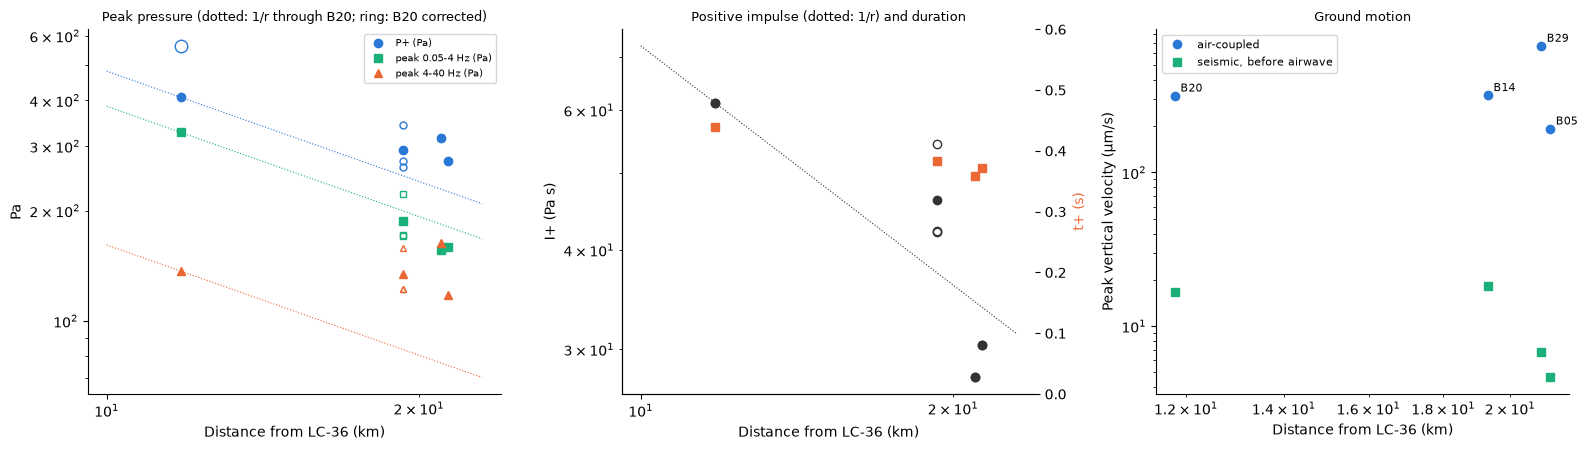

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
dd = np.linspace(10, 23, 50)
ax = axs[0]
for k, mk, col in (('P_pos_Pa', 'o', '#2a78d6'), ('P_low_0p05_4Hz_Pa', 's', '#1baf7a'), ('P_high_4_40Hz_Pa', '^', '#eb6834')):
    ax.loglog(bp.distance_km, np.abs(bp[k]), mk, mfc='none', color=col, ms=5)
    ax.loglog(per.distance_km, per[k], mk, color=col, label=METRICS[k])
    ref = per[k].iloc[0] * per.distance_km.iloc[0]
    ax.loglog(dd, ref / dd, ':', color=col, lw=0.8)
ax.plot(per.distance_km.iloc[0], per.P_pos_Pa.iloc[0] / dec.ratio_P.min(), 'o', mfc='none', mec='#2a78d6', ms=9)
ax.set(xlabel='Distance from LC-36 (km)', ylabel='Pa', title='Peak pressure (dotted: 1/r through B20; ring: B20 corrected)')
ax.legend(fontsize=7)
ax = axs[1]
ax.loglog(bp.distance_km, bp.I_pos_Pa_s, 'o', mfc='none', color='#333333')
ax.loglog(per.distance_km, per.I_pos_Pa_s, 'o', color='#333333', label='I+ (Pa s)')
ax.loglog(dd, per.I_pos_Pa_s.iloc[0] * per.distance_km.iloc[0] / dd, ':', color='#333333', lw=0.8)
ax2 = ax.twinx()
ax2.plot(per.distance_km, per.t_pos_s, 's', color='#eb6834')
ax2.set_ylabel('t+ (s)', color='#eb6834')
ax2.set_ylim(0, 0.6)
ax.set(xlabel='Distance from LC-36 (km)', ylabel='I+ (Pa s)', title='Positive impulse (dotted: 1/r) and duration')
ax = axs[2]
ax.loglog(gm.distance_km, gm.v_aircoupled_um_s, 'o', color='#2a78d6', label='air-coupled')
ax.loglog(gm.distance_km, gm.v_seismic_um_s, 's', color='#1baf7a', label='seismic, before airwave')
for s_, r in gm.iterrows():
    ax.annotate(s_, (r.distance_km, r.v_aircoupled_um_s), xytext=(4, 3), textcoords='offset points', fontsize=8)
ax.set(xlabel='Distance from LC-36 (km)', ylabel='Peak vertical velocity (µm/s)', title='Ground motion')
ax.legend(fontsize=8)
for a in axs:
    a.title.set_fontsize(9)
fig.tight_layout()
fig.savefig(OUT / 'amplitude_vs_distance.png', dpi=150, bbox_inches='tight')

## What this shows

* **Blast parameters.** Positive peaks are 407 Pa at B20 (11.8 km) and 264–342 Pa at 19.3–21.3 km.
  Positive-phase durations are 0.36–0.44 s and positive impulses 28–61 Pa s. Negative phases are 3–7
  times smaller than positive ones.
* **Two frequency regimes decay differently.** Below 4 Hz the peak falls as $r^{-1.23 \pm 0.09}$, close to
  spherical spreading (consistent with the reduced spectra of notebook 30). Above 4 Hz it hardly decays
  at all ($n = 0.0 \pm 0.3$, or 0.6 with B20 corrected). The broadband peak combines the two and falls
  only as $r^{-0.6}$. Positive impulse, dominated by the low frequencies, falls as $r^{-1.2 \pm 0.5}$:
  $I_+ r$ is 580–1050 Pa s km at every station.
* **B20's 100 samples/s.** Decimating the 500 samples/s records lowers the B14 peaks by 26–28% (B14's shock
  front is very steep) but B29 and B05 by only 1–4%. Impulse and duration are unaffected (within 2%). B20's
  peak may therefore be under-read by up to about 28%. If it is, the peak decays as $r^{-1.15}$, close to
  spherical spreading. Impulse is the robust amplitude measure here.
* **Positive-phase duration** shortens slightly with distance (0.44 s at B20 to 0.36–0.38 s at 19–21 km).
  Weak-shock theory predicts lengthening, so this points to propagation effects (or B20's lower sampling
  rate) and needs modelling.
* **Yield (order of magnitude).** Kinney & Graham (1985), treating the explosion as a surface burst, give a
  TNT equivalent of about 145 t from the peak overpressures (94–246 t across stations) and about 375 t
  from the positive-phase durations (307–573 t). The factor of 2–3 between them fits a propellant
  explosion (slower energy release than TNT gives a longer, weaker pulse) and refraction in a night-time
  atmosphere. Read it as "a few hundred tonnes of TNT", to be refined with a propagation model and the
  infraBSU calibrations.
* **Ground motion.** Air-coupled peak velocities are 190–670 µm/s with no clear trend over this distance
  range: they follow site coupling (B29 is highest; see the compliance in notebook 28). The seismic
  wavetrain ahead of the airwave is 5–18 µm/s, 10–100 times smaller.